# Anomaly Detection

This notebook builds an Isolation Forest workflow for detecting machine records that differ from learned normal operating behavior. The model is trained on **7,729 normal training records** and evaluated on **2,000 test records**.

The goal is not to classify failure directly. The analysis asks:

- Which records look unusual compared with normal behavior?
- How strongly do anomaly flags overlap with recorded failures?
- Which sensor values make selected records look unusual?
- What are the limitations of treating abnormality as failure risk?

## Step 1: Import Libraries and Load Dataset

The same AI4I dataset and six leakage-safe features used in preprocessing are loaded. `IsolationForest` provides the anomaly detector, while the failure labels are retained only for later comparison.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

df = pd.read_csv('../../data/raw/ai4i2020.csv')
df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2: Select Safe Features

The model receives **six machine-condition features**: `Type`, air temperature, process temperature, rotational speed, torque, and tool wear. The feature matrix has shape **(10,000, 6)**.

`Machine failure` and the five failure-mode indicators are excluded from model inputs. They are labels used only for evaluation and interpretation. Including them would reveal failure information to the model and create target leakage.

In [2]:
input_features = [
    'Type',
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

numeric_features = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

# First "responsible AI" checkpoint
# Data leakage detection is part of responsible modeling, not just accuracy engineering. 
# We are dropping these 5 columns before training on Machine failure.
X = df[input_features].copy()
y = df['Machine failure'].copy()
failure_modes = df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].copy()

# Check target variable balance BEFORE preprocessing
print("Target variable balance (before split):")
print(df["Machine failure"].value_counts())
print(f"Failure rate: {df['Machine failure'].mean():.2%}")

print('X shape:', X.shape)
print("y shape:", y.shape)
X.head()

Target variable balance (before split):
Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39%
X shape: (10000, 6)
y shape: (10000,)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


## Step 3: Train/Test Split

The data is split before encoding and scaling. Stratification produces **8,000 training records** containing 271 failures and **2,000 test records** containing 68 failures. The training and test failure rates remain approximately 3.39% and 3.40%, respectively.

The labels are not prediction targets for Isolation Forest. They are retained so that anomaly-failure overlap can be measured after the model produces its flags.


In [16]:
# Train/test split before encoding and scaling
# Stratification keeps failure/no-failure proportions consistent in both sets

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set size: {X_train_raw.shape[0]} samples")
print(f"Test set size: {X_test_raw.shape[0]} samples")
print(f"\nTraining set failure rate: {y_train.mean():.2%}")
print(f"Test set failure rate: {y_test.mean():.2%}")
print(f"Test set failure count: {y_test.sum()}")


Training set size: 8000 samples
Test set size: 2000 samples

Training set failure rate: 3.39%
Test set failure rate: 3.40%
Test set failure count: 68


## Step 4: Encode and Scale Features

`Type` is one-hot encoded and the five numerical sensors are standardized. The processed training matrix has shape **(8,000, 7)** and the processed test matrix has shape **(2,000, 7)**. The scaler is fitted only on training data to prevent evaluation leakage.

Scaling is not essential for the tree-based Isolation Forest, but it keeps the pipeline consistent and supports the later z-score explanation.


In [4]:
# Encode categorical feature product Type
X_train_encoded = pd.get_dummies(X_train_raw, columns=['Type'], drop_first=True, dtype=int)
X_test_encoded = pd.get_dummies(X_test_raw, columns=['Type'], drop_first=True, dtype=int)

# Making sure train and test have the same columns
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Using StandardScaler to scale numeric features of both test and train sets to have mean~0 and std=1
# Scaling is not essential for Isolation Forest because it is tree-based, 
# but it keeps preprocessing consistent and helps the later z-score explanation.
scaler = StandardScaler()

X_train_processed = X_train_encoded.copy()
X_test_processed = X_test_encoded.copy()

X_train_processed[numeric_features] = scaler.fit_transform(X_train_encoded[numeric_features])
X_test_processed[numeric_features] = scaler.transform(X_test_encoded[numeric_features])

print('Processed train shape:', X_train_processed.shape)
print('Processed test shape:', X_test_processed.shape)
X_train_processed.head()

Processed train shape: (8000, 7)
Processed test shape: (2000, 7)


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Type_L,Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0,1
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0,1
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0,1
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,1,0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,1,0


## Step 5: Train on Normal Records

For this anomaly detection experiment, the model is trained on **7,729 normal records**. The **271 failure records** in the training partition are excluded.

Intuition:

- normal records teach the model what typical machine behavior looks like
- records that do not fit this normal pattern may be flagged as anomalies

The failure labels are used here only to construct the normal reference set and to evaluate results afterward. This assumes that the provided normal labels are reliable.


In [5]:
train_data_normal = y_train == 0
X_train_normal = X_train_processed.loc[train_data_normal]

print('All training records:', len(X_train_processed))
print('Normal training records used for anomaly detector:', len(X_train_normal))
print('Failure records excluded from anomaly detector training:', (~train_data_normal).sum())

All training records: 8000
Normal training records used for anomaly detector: 7729
Failure records excluded from anomaly detector training: 271


Isolation Forest itself is an unsupervised algorithm because it does not learn a target variable.

However, labels are used to select the normal reference records. Therefore, the complete experimental design is more accurately described as **novelty detection** or a semi-supervised anomaly-detection setup rather than fully label-free unsupervised learning.

## Step 6: Fit the Anomaly Detection Model

Isolation Forest isolates records using random feature selections and random split points. Records requiring fewer tree splits to isolate are treated as more unusual. The fitted model returns:

- `1` for normal records
- `-1` for anomalous records

For project consistency, these values are converted into:

- `0` for normal
- `1` for anomaly


In [6]:
anomaly_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_model.fit(X_train_normal)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


`contamination=0.05` tells the model to set its decision threshold assuming approximately 5% of fitted observations should be considered anomalous.

It does not mean:

- 5% of machines will fail,

- anomaly probability is 5%, or

- the dataset failure rate is 5%.

It is a threshold-setting assumption and should be justified or tested through sensitivity analysis.

The fitted threshold flags **113 of 2,000 test records**, giving an observed anomaly rate of **5.65%**.

The test anomaly rate does not have to equal exactly 5% because the threshold was learned from training data.

The fitted detector is now applied to the untouched test records. This provides an out-of-sample estimate of how the learned normal-behavior boundary responds to new observations.

## Step 7: Generate Test-Set Anomaly Predictions

In [7]:
# prediction using the above fitted/trained model, now on the test set.
raw_predictions = anomaly_model.predict(X_test_processed)
anomaly_flag = (raw_predictions == -1).astype(int)

print('Normal test records predicted:', (anomaly_flag == 0).sum())
print('Anomalous test records predicted:', (anomaly_flag == 1).sum())
print('Anomaly rate:', f'{anomaly_flag.mean():.2%}')

Normal test records predicted: 1887
Anomalous test records predicted: 113
Anomaly rate: 5.65%


Scikit-learn returns `1` for normal and `-1` for anomaly. The notebook converts these to `0` for normal and `1` for anomalous so the flags are easier to compare with the binary failure label.

The current run predicts **1,887 normal test records** and **113 anomalous test records**. The conversion changes only the representation, not the learned model or threshold.

## Step 8: Compare Anomaly Flags With Actual Failures

Anomaly detection is not the same as failure classification.

A record can be unusual without being a failure, and a failure may not always look unusual. The overlap matrix is:

| Actual condition | Predicted normal | Predicted anomaly |
|---|---:|---:|
| No failure | 1,835 | 97 |
| Failure | 52 | 16 |

The anomaly flags capture **16 of 68 failures**, giving an overlap recall of **23.53%**. Only **16 of 113 anomalies** are labelled failures, giving an overlap precision of **14.16%** and F1-score of **17.68%**. These are diagnostic overlap measures, not evidence that Isolation Forest was trained as a failure classifier.

In [9]:
print('Confusion matrix: rows = actual failure, columns = predicted anomaly')
print(confusion_matrix(y_test, anomaly_flag))
print()

# print(y_test)
normal_test_data = y_test[y_test == 0]
failure_test_data = y_test[y_test == 1]
print(len(normal_test_data), len(failure_test_data))

print(anomaly_flag)

print(classification_report(y_test, anomaly_flag, target_names=['Normal', 'Failure/Anomaly'], zero_division=0))

Confusion matrix: rows = actual failure, columns = predicted anomaly
[[1835   97]
 [  52   16]]

1932 68
[0 0 0 ... 0 0 0]
                 precision    recall  f1-score   support

         Normal       0.97      0.95      0.96      1932
Failure/Anomaly       0.14      0.24      0.18        68

       accuracy                           0.93      2000
      macro avg       0.56      0.59      0.57      2000
   weighted avg       0.94      0.93      0.93      2000



## Step 9: Inspect the Most Anomalous Records

The anomaly score ranks unusualness: lower and especially negative values indicate more unusual records. Failure records have a lower mean score (**0.03385**) than no-failure records (**0.08755**), but the score ranges overlap. Therefore, failures tend to look more unusual on average without forming a completely separate group.


In [10]:
anomaly_scores = anomaly_model.decision_function(X_test_processed)

results = X_test_raw.copy()
results['Machine failure'] = y_test.values
results['anomaly_flag'] = anomaly_flag
results['anomaly_score'] = anomaly_scores

most_anomalous = results.sort_values('anomaly_score').head(10)
most_anomalous

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,anomaly_flag,anomaly_score
989,M,296.2,307.0,2119,18.3,159,0,1,-0.095770
4296,L,301.8,310.2,2825,5.8,215,1,1,-0.082639
7997,M,301.0,312.2,2710,9.7,143,1,1,-0.079849
7086,L,300.6,310.4,2514,13.4,215,0,1,-0.078091
4899,L,303.6,312.3,2168,17.7,219,0,1,-0.078009
2080,L,299.3,309.2,2280,15.4,207,0,1,-0.069453
921,H,295.5,305.9,1593,37.2,197,0,1,-0.068339
8110,H,300.3,311.8,2141,18.5,204,0,1,-0.065517
4985,M,303.8,313.0,1789,23.5,215,0,1,-0.064318
380,L,297.5,308.3,2564,12.8,127,1,1,-0.063714


The ten lowest-scoring records show several recurring patterns: very high rotational speed, low torque, high tool wear, and unusual temperature values. Three of these ten records are labelled failures. The most anomalous record has a score of **-0.09577** and is not a labelled failure, illustrating that statistical abnormality does not automatically mean failure.

## Step 10: Simple Feature-Deviation Explanations

A simple explanation approach is to compare each anomalous record with the average normal training record.

For each record, we calculate how many standard deviations each numeric feature is from the normal training mean.

Large absolute values mean that a feature is far from the normal reference mean. For example, one flagged failure has rotational speed **7.60 standard deviations** and torque **3.56 standard deviations** away from the normal mean.

This is an interpretable deviation summary, not a direct explanation of Isolation Forest's internal tree paths. It also considers each feature separately and can miss joint anomalies involving feature combinations.

In [11]:
normal_means = X_train_raw.loc[y_train == 0, numeric_features].mean()
normal_stds = X_train_raw.loc[y_train == 0, numeric_features].std()

def explain_record(row):
    z_scores = ((row[numeric_features] - normal_means) / normal_stds).abs()
    top_features = z_scores.sort_values(ascending=False).head(3)
    # print(', '.join([f'{feature}: {value:.2f} std away' for feature, value in top_features.items()]))
    return ', '.join([f'{feature}: {value:.2f} std away' for feature, value in top_features.items()])

explanation_table = most_anomalous.copy()
explanation_table['simple_explanation'] = explanation_table.apply(explain_record, axis=1)

explanation_table[[
    'Type',
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
    'Machine failure',
    'anomaly_flag',
    'anomaly_score',
    'simple_explanation'
]]

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,anomaly_flag,anomaly_score,simple_explanation
989,M,296.2,307.0,2119,18.3,159,0,1,-0.095770,"Rotational speed: 3.42 std away, Torque: 2.24 ..."
4296,L,301.8,310.2,2825,5.8,215,1,1,-0.082639,"Rotational speed: 7.60 std away, Torque: 3.56 ..."
7997,M,301.0,312.2,2710,9.7,143,1,1,-0.079849,"Rotational speed: 6.92 std away, Torque: 3.15 ..."
7086,L,300.6,310.4,2514,13.4,215,0,1,-0.078091,"Rotational speed: 5.76 std away, Torque: 2.76 ..."
4899,L,303.6,312.3,2168,17.7,219,0,1,-0.078009,"Rotational speed: 3.71 std away, Torque: 2.31 ..."
2080,L,299.3,309.2,2280,15.4,207,0,1,-0.069453,"Rotational speed: 4.38 std away, Torque: 2.55 ..."
921,H,295.5,305.9,1593,37.2,197,0,1,-0.068339,"Process temperature: 2.76 std away, Air temper..."
8110,H,300.3,311.8,2141,18.5,204,0,1,-0.065517,"Rotational speed: 3.55 std away, Torque: 2.22 ..."
4985,M,303.8,313.0,1789,23.5,215,0,1,-0.064318,"Process temperature: 2.03 std away, Air temper..."
380,L,297.5,308.3,2564,12.8,127,1,1,-0.063714,"Rotational speed: 6.06 std away, Torque: 2.82 ..."


## Step 11: Observations

Isolation Forest flagged **113 of 2,000 test records (5.65%)** as anomalous. Of the 68 actual failures, 16 were flagged and 52 were missed by the anomaly threshold. The detector also flagged 97 records without a failure label. This confirms that anomaly detection and failure classification answer different questions.

Flagged records have much higher average rotational speed (**1,781.27 rpm versus 1,521.79 rpm**) and lower average torque (**32.05 Nm versus 40.39 Nm**) than unflagged records. They also have somewhat greater average tool wear (**120.35 versus 108.34 minutes**). The most extreme explanations repeatedly highlight speed, torque, wear, and temperature deviations.

The anomaly score remains useful as an unusualness signal even though it is not a failure probability. Explainability is needed to show which sensor conditions accompany each flag and to prevent users from treating every anomaly as a confirmed failure.


## Step 12: Milestone Summary Metrics

For the milestone, it is useful to report a few simple numbers:

- total test records
- number of records flagged as anomalous
- anomaly rate
- actual failures in the test set
- actual failures captured by anomaly flags

The measured summary is: 2,000 test records, 68 failures, 113 anomaly flags, 16 failures flagged, 97 no-failure records flagged, and 52 failures not flagged. These values should be reported together so that the anomaly rate is not presented without its practical overlap and limitations.

In [12]:
actual_failures = (y_test == 1).sum()
flagged_anomalies = anomaly_flag.sum()
failures_flagged_as_anomalies = ((y_test == 1) & (anomaly_flag == 1)).sum()
normal_records_flagged_as_anomalies = ((y_test == 0) & (anomaly_flag == 1)).sum()
failures_not_flagged = ((y_test == 1) & (anomaly_flag == 0)).sum()

summary_metrics = pd.DataFrame({
    'metric': [
        'total_test_records',
        'actual_failures_in_test_set',
        'records_flagged_as_anomalous',
        'anomaly_rate',
        'failures_flagged_as_anomalous',
        'normal_records_flagged_as_anomalous',
        'failures_not_flagged_as_anomalous'
    ],
    'value': [
        len(y_test),
        actual_failures,
        flagged_anomalies,
        f'{anomaly_flag.mean():.2%}',
        failures_flagged_as_anomalies,
        normal_records_flagged_as_anomalies,
        failures_not_flagged
    ]
})

summary_metrics

,metric,value
0,total_test_records,2000
1,actual_failures_in_test_set,68
2,records_flagged_as_anomalous,113
3,anomaly_rate,5.65%
4,failures_flagged_as_anomalous,16
5,normal_records_flagged_as_anomalous,97
6,failures_not_flagged_as_anomalous,52


## Step 13: Save Milestone Outputs

Saving the measured results makes the experiment reproducible and provides traceable evidence for the milestone report and presentation.

We save:

- all test records with anomaly flags and scores
- the top anomalous records with simple explanations
- summary metrics

In [13]:
from pathlib import Path

output_dir = Path('../../outputs')
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(output_dir / 'anomaly_detection_test_results.csv', index=False)
explanation_table.to_csv(output_dir / 'top_anomaly_explanations.csv', index=False)
summary_metrics.to_csv(output_dir / 'anomaly_detection_summary_metrics.csv', index=False)

print('Saved files:')
print(output_dir / 'anomaly_detection_test_results.csv')
print(output_dir / 'top_anomaly_explanations.csv')
print(output_dir / 'anomaly_detection_summary_metrics.csv')

Saved files:
../../outputs/anomaly_detection_test_results.csv
../../outputs/top_anomaly_explanations.csv
../../outputs/anomaly_detection_summary_metrics.csv


## Step 14: Report-Ready Anomaly Detection Conclusion

The anomaly-detection experiment used six machine-condition features from the AI4I 2020 dataset. After a stratified split, Isolation Forest was fitted on 7,729 normal training records to learn a reference for typical operation. With contamination set to 0.05, the model flagged 113 of 2,000 test records as anomalous, corresponding to an observed anomaly rate of 5.65%.

The flags overlapped with 16 of the 68 test failures, giving 23.53% overlap recall. Ninety-seven anomaly flags occurred on records without a failure label, and 52 failures were not flagged. Failure records nevertheless received lower anomaly scores on average than no-failure records (0.03385 versus 0.08755), showing that failures tended to be more unusual while still overlapping substantially with normal operating behavior.

Feature-deviation explanations showed that unusual rotational speed, torque, tool wear, and temperature values frequently characterized the most anomalous records. Flagged records averaged 1,781.27 rpm and 32.05 Nm, compared with 1,521.79 rpm and 40.39 Nm for unflagged records. These results support using anomaly detection as an unusual-behavior screening tool, but not as a direct substitute for failure classification or as proof that a flagged machine will fail.


## Step 15: Visualize Anomaly Scores

Now that we have anomaly scores, we should visualize them.

Why this matters:

- A table shows individual records.
- A plot shows the overall behavior of the model.
- We can see whether failure records tend to receive lower anomaly scores than normal records.

Recall: lower anomaly score means more unusual. In the current results, failure records have a mean score of **0.03385** and median of **0.03814**, while no-failure records have a mean of **0.08755** and median of **0.09220**. The overlapping distributions explain why a single anomaly threshold cannot identify every failure.

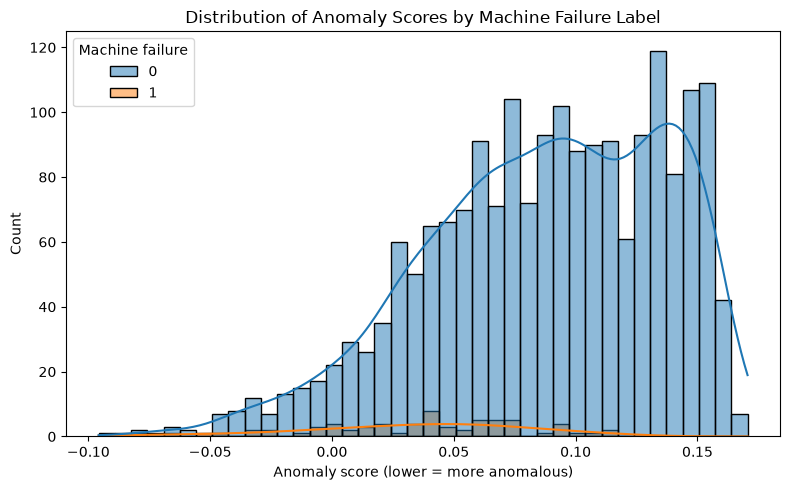

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=results, x='anomaly_score', hue='Machine failure', bins=40, kde=True)
plt.title('Distribution of Anomaly Scores by Machine Failure Label')
plt.xlabel('Anomaly score (lower = more anomalous)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Step 16: Compare Sensor Values by Anomaly Flag

Next, we compare sensor values for records flagged as normal versus anomalous.

This helps answer:

- What sensor patterns are common among anomalous records?
- Do anomalous records show different torque, speed, wear, or temperature behavior?

The largest mean differences occur in rotational speed and torque. Flagged records average **1,781.27 rpm**, **32.05 Nm**, and **120.35 minutes of tool wear**; unflagged records average **1,521.79 rpm**, **40.39 Nm**, and **108.34 minutes of tool wear**.

In [71]:
feature_summary_by_anomaly = results.groupby('anomaly_flag')[numeric_features].mean().round(2)
feature_summary_by_anomaly

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
anomaly_flag,,,,,
0,299.98,310.00,1521.79,40.39,108.34
1,300.35,310.11,1781.27,32.05,120.35


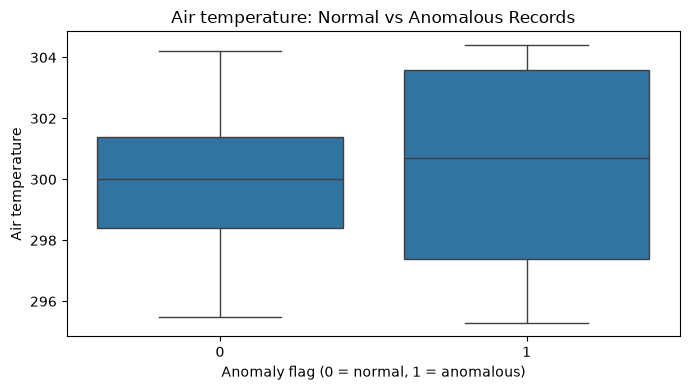

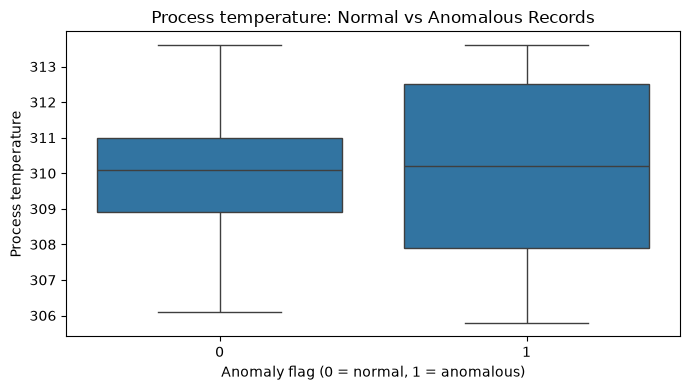

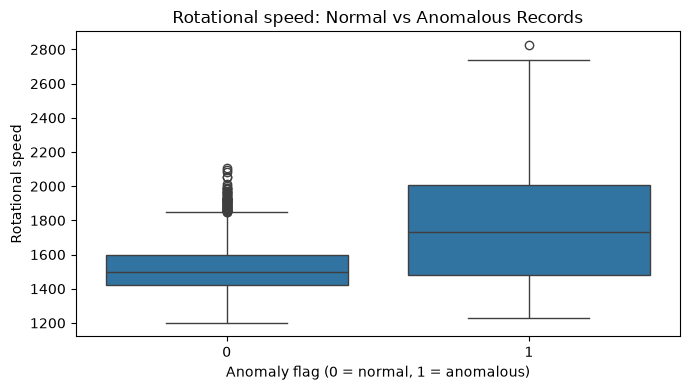

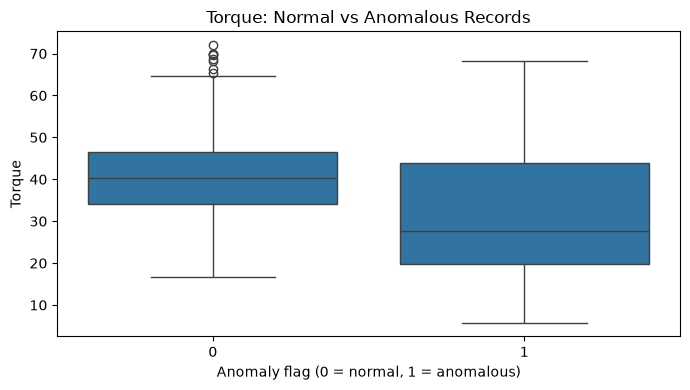

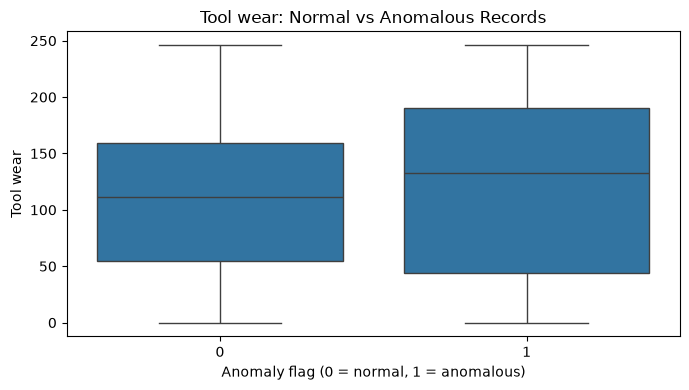

In [72]:
for feature in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=results, x='anomaly_flag', y=feature)
    plt.title(f'{feature}: Normal vs Anomalous Records')
    plt.xlabel('Anomaly flag (0 = normal, 1 = anomalous)')
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

## Step 17: Visualize Important Sensor Relationships

From the top anomaly explanations, rotational speed and torque appear very important.

A scatter plot helps reveal joint behavior that individual z-scores cannot capture. Many flagged records occupy the high-speed, low-torque region, consistent with the strong inverse correlation between speed and torque observed during exploration.

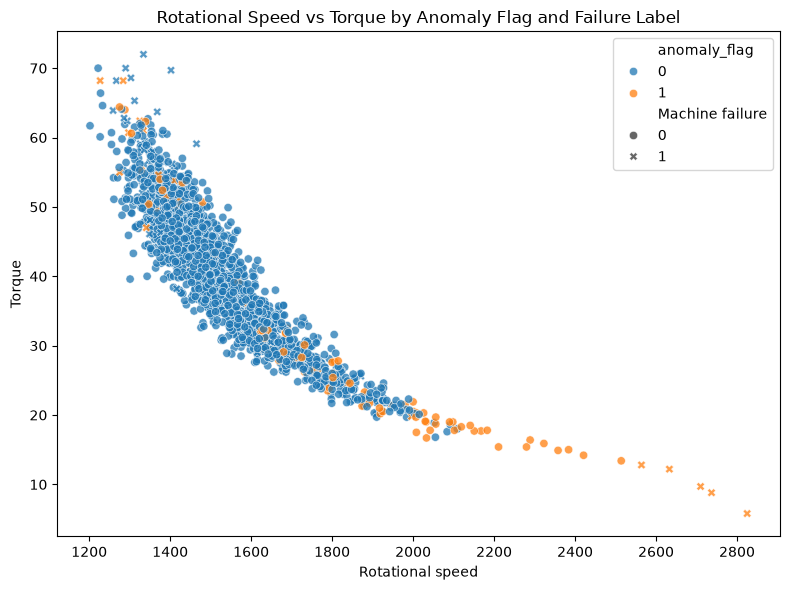

In [15]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=results,
    x='Rotational speed',
    y='Torque',
    hue='anomaly_flag',
    style='Machine failure',
    alpha=0.75
)
plt.title('Rotational Speed vs Torque by Anomaly Flag and Failure Label')
plt.xlabel('Rotational speed')
plt.ylabel('Torque')
plt.tight_layout()
plt.show()

## Step 18: Visualization Findings

Failure records tend to receive lower anomaly scores than no-failure records, but the distributions overlap. The boxplots show that flagged records differ most clearly in rotational speed and torque, with smaller differences in tool wear and temperature. The speed-torque scatter plot reveals a recurring high-speed, low-torque anomaly region.

Together, these visualizations connect the model's anomaly flags to understandable operating patterns. They also expose the method's limitation: not every failure lies in an extreme sensor region, and not every extreme region corresponds to a recorded failure.